<a href="https://colab.research.google.com/github/KangabireMuhozaMerveille/churn-customer-analysis/blob/master/churn_customer_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance

# Display settings
pd.set_option("display.max_columns", None)


sns.set_theme(style="whitegrid")

In [5]:
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [20]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [21]:
# 1. Create a working copy
df_clean = df.copy()

# 2. Remove unnecessary whitespace from column names and text
df_clean.columns = df_clean.columns.str.strip()

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# 3. Convert TotalCharges into numerical data
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# 4. Check data quality
print("Dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())
print("\nMissing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# 5. Inspect numerical variables
display(df_clean.describe())

# 6. Inspect target distribution
print("\nChurn distribution:")
print(df_clean["Churn"].value_counts(normalize=True) * 100)

Dataset shape: (7043, 21)
Duplicate rows: 0
Duplicate customer IDs: 0

Missing values:
TotalCharges    11
dtype: int64


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000



Churn distribution:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [22]:
# Handle missing TotalCharges
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Convert SeniorCitizen to categorical
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].astype(str)

# Confirm the data is ready
print("Missing values:", df_clean.isnull().sum().sum())
print("Dataset shape:", df_clean.shape)

Missing values: 0
Dataset shape: (7043, 21)


Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


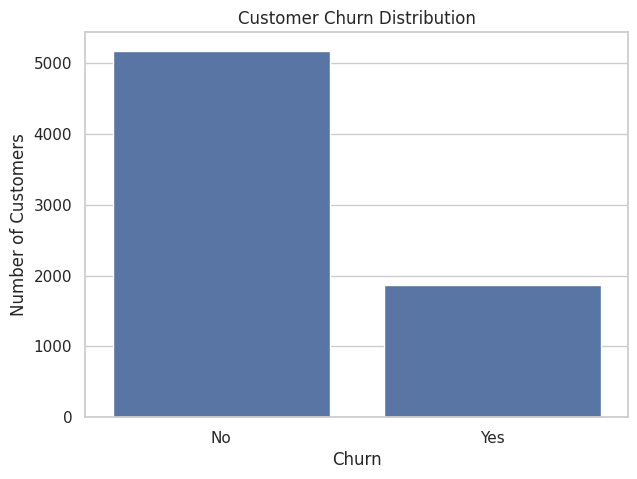

In [23]:
# Churn distribution
churn_counts = df_clean["Churn"].value_counts()
churn_percentage = df_clean["Churn"].value_counts(normalize=True) * 100

print("Churn counts:")
print(churn_counts)

print("\nChurn percentages:")
print(churn_percentage.round(2))

# Visualize churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

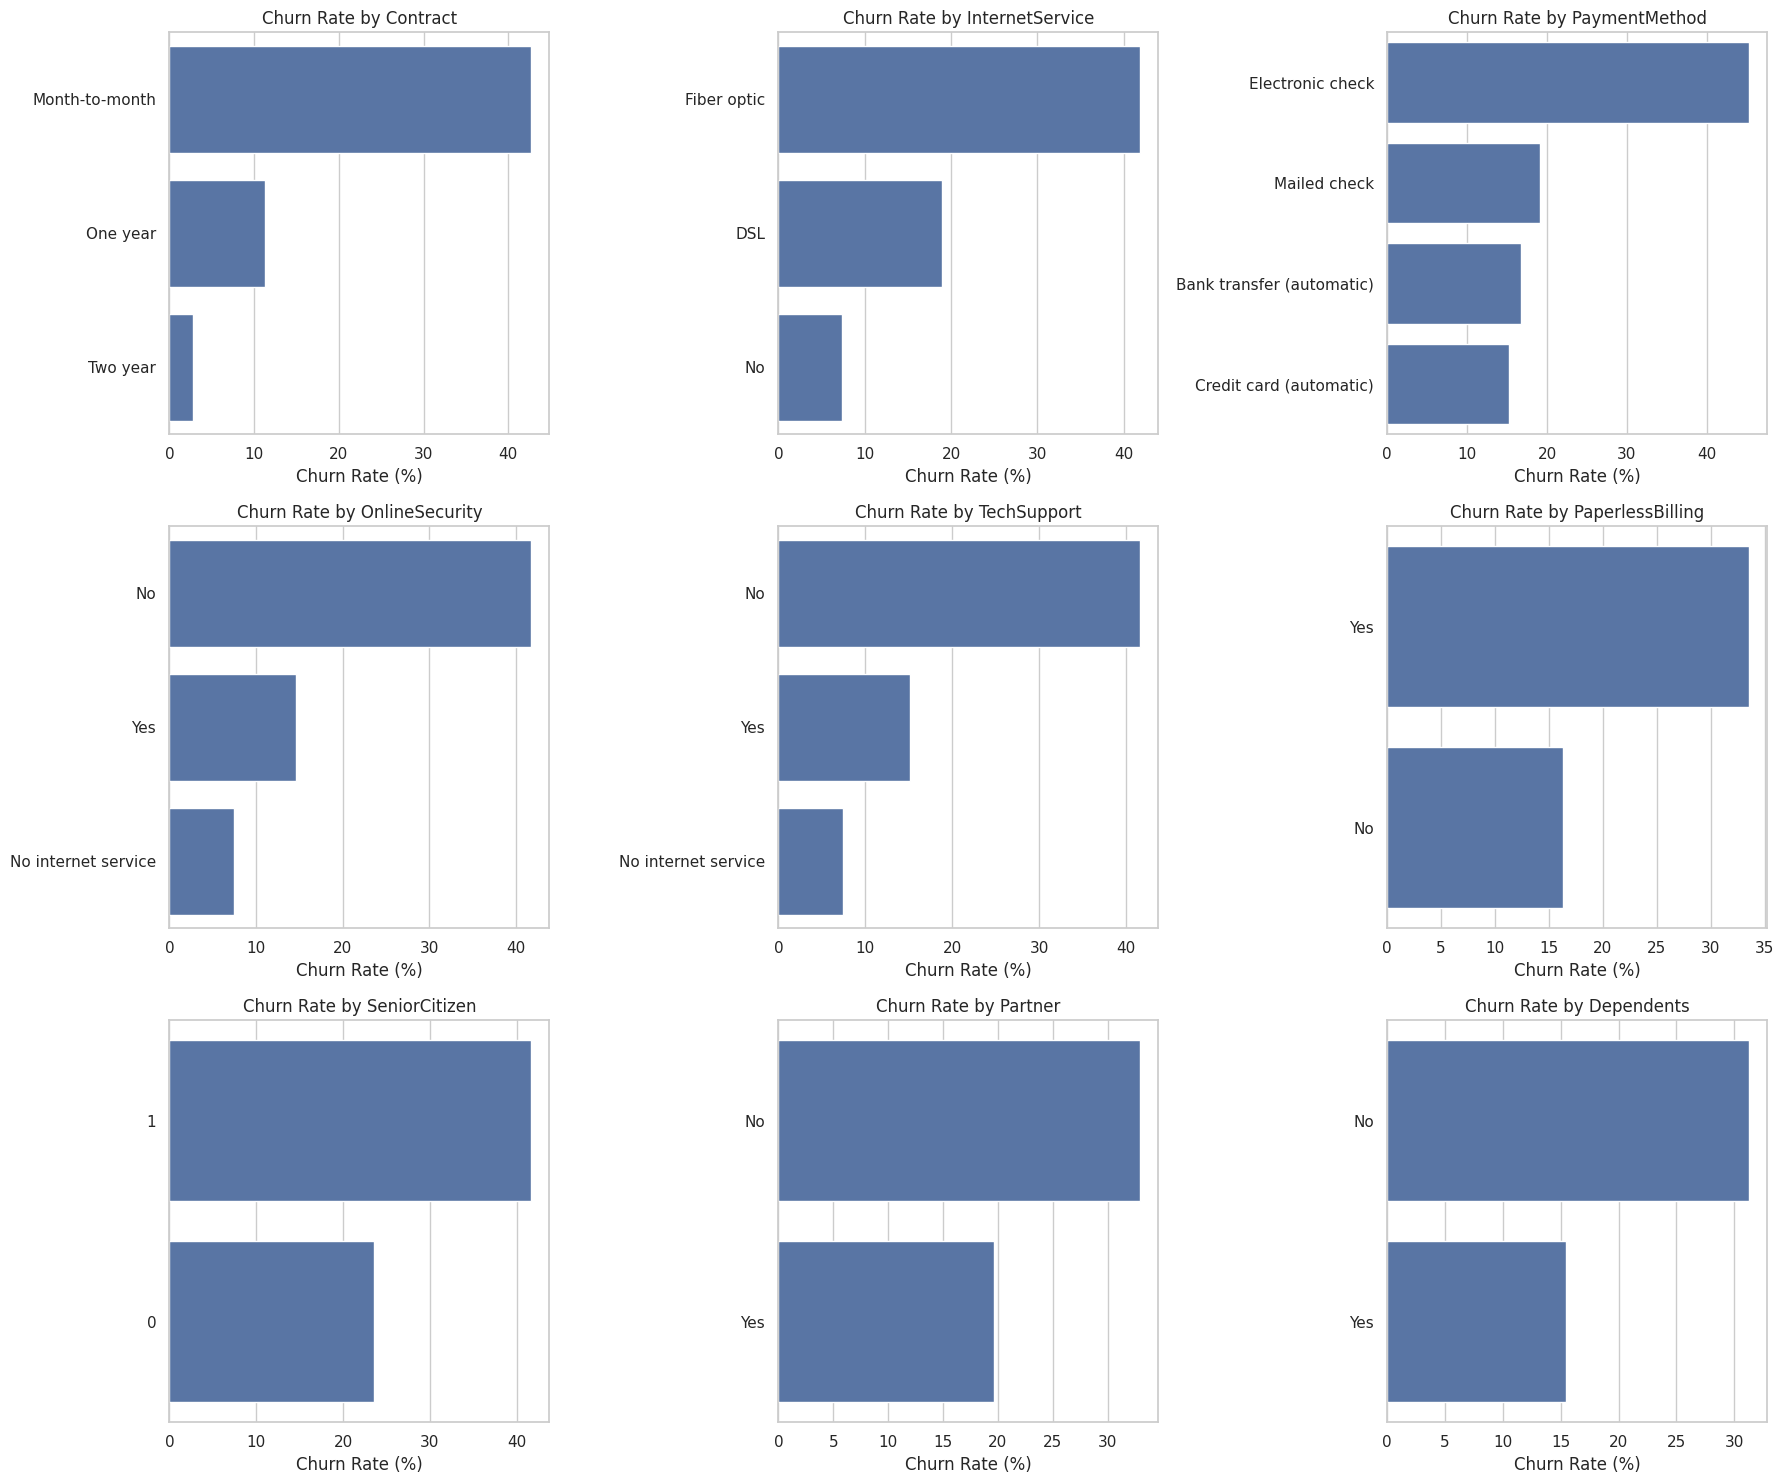

In [24]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    churn_rate = (
        df_clean.groupby(feature, observed=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(x=churn_rate.values, y=churn_rate.index, ax=axes[i])
    axes[i].set_title(f"Churn Rate by {feature}")
    axes[i].set_xlabel("Churn Rate (%)")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

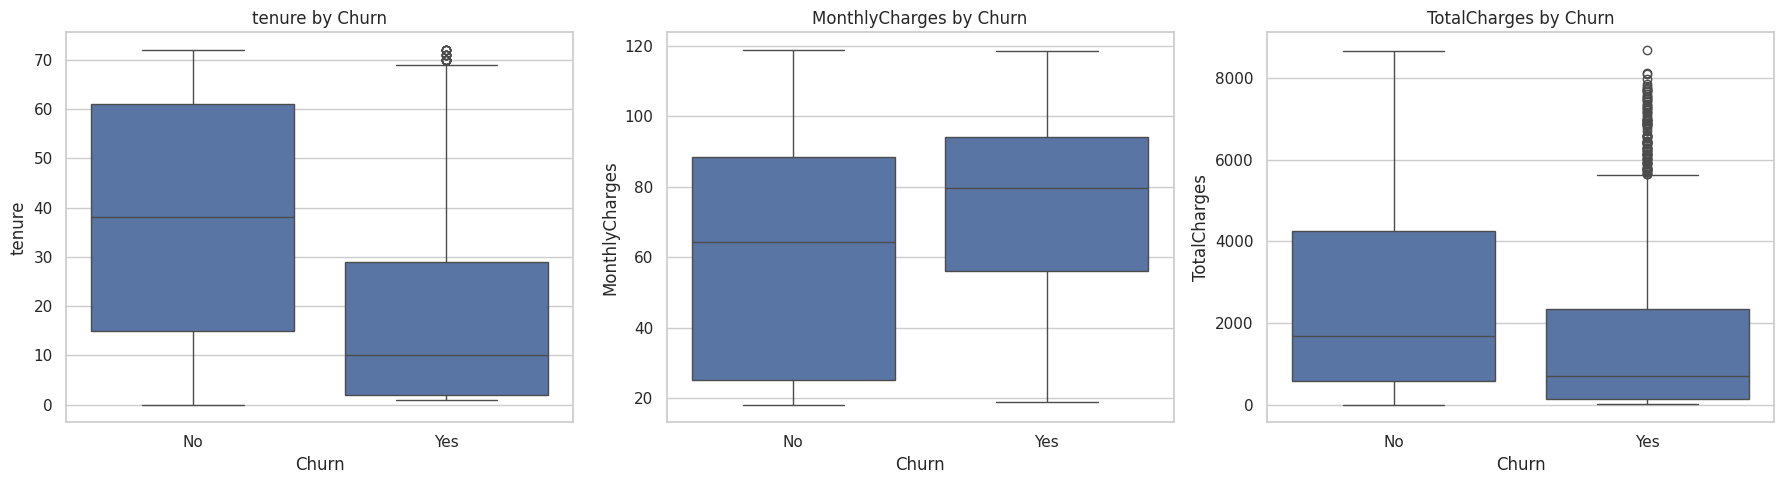

In [25]:
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(numerical_features):
    sns.boxplot(data=df_clean, x="Churn", y=feature, ax=axes[i])
    axes[i].set_title(f"{feature} by Churn")

plt.tight_layout()
plt.show()

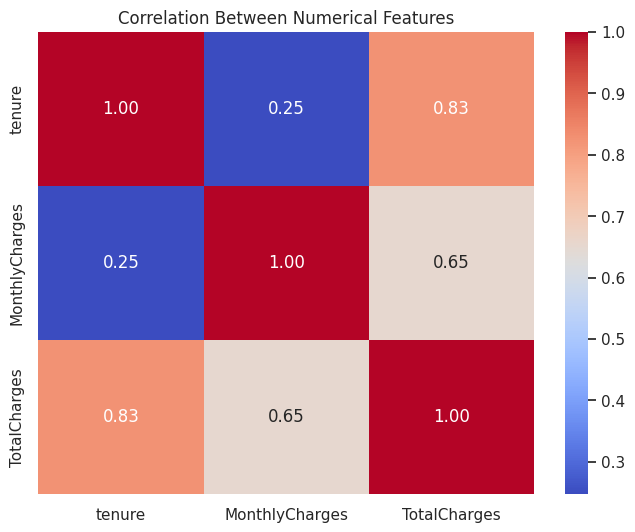

In [26]:
plt.figure(figsize=(8, 6))

correlation = df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.show()

In [27]:
# Average tenure and monthly charges by churn status
churn_summary = df_clean.groupby("Churn").agg(
    Average_Tenure=("tenure", "mean"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Total_Charges=("TotalCharges", "mean"),
    Customer_Count=("customerID", "count")
)

display(churn_summary.round(2))

# Churn rate by contract type
contract_churn = (
    df_clean.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("\nChurn rate by contract type:")
display(contract_churn.round(2))

,Average_Tenure,Average_Monthly_Charges,Average_Total_Charges,Customer_Count
Churn,,,,
No,37.57,61.27,2549.91,5174
Yes,17.98,74.44,1531.80,1869



Churn rate by contract type:


,Churn
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [29]:
# Create features and target
X = df_clean.drop(columns=["customerID", "Churn"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split data before preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining set:", X_train.shape)
print("Testing set:", X_test.shape)

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training set: (5634, 19)
Testing set: (1409, 19)


In [30]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [31]:
models = {
    "Dummy Classifier": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline

print("All models trained successfully!")

All models trained successfully!


In [32]:
results = []

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Dummy Classifier,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415,0.6325
Random Forest,0.7857,0.6286,0.4706,0.5382,0.8218,0.6085
Gradient Boosting,0.8048,0.6701,0.5214,0.5865,0.8454,0.6640


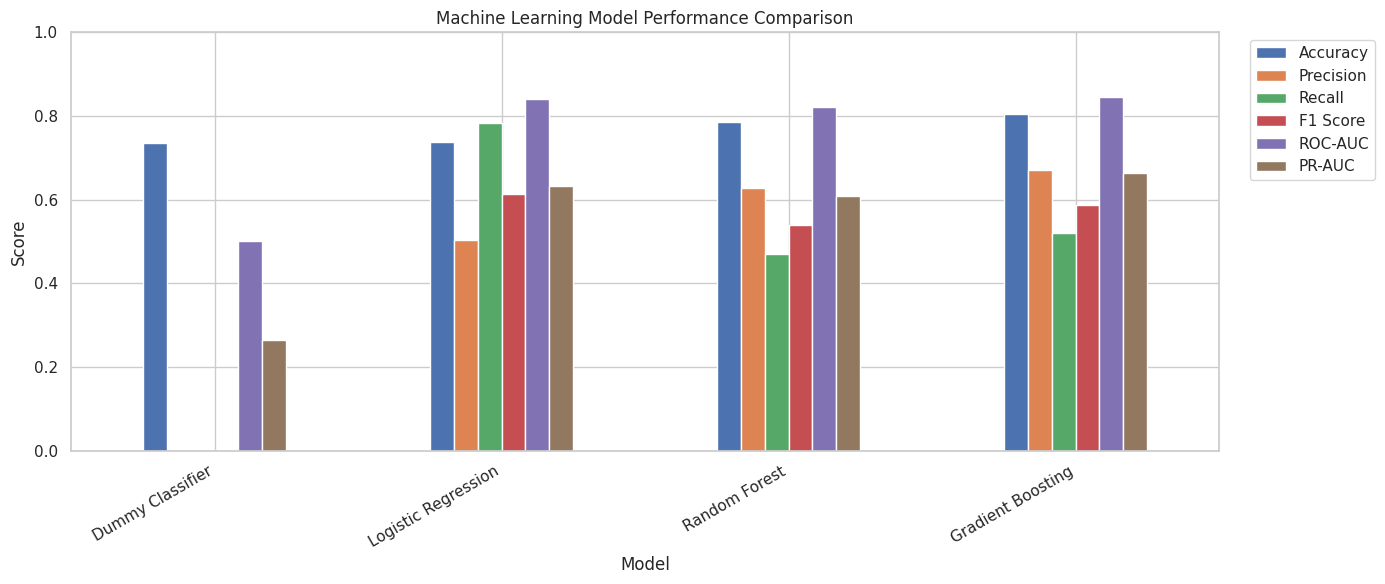

In [33]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [34]:
best_model_name = results_df["F1 Score"].idxmax()
best_model = pipelines[best_model_name]

print("Best model:", best_model_name)

y_pred = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

Best model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



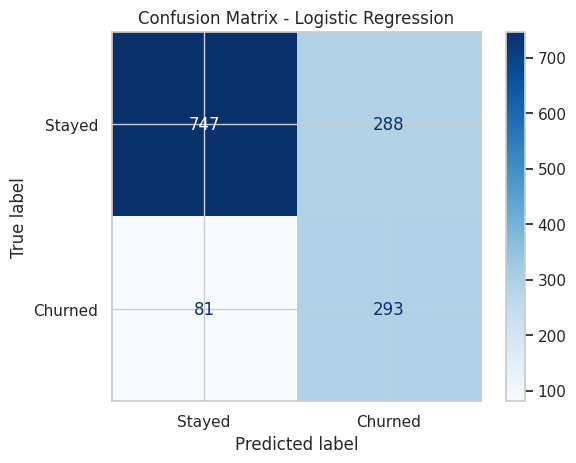

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

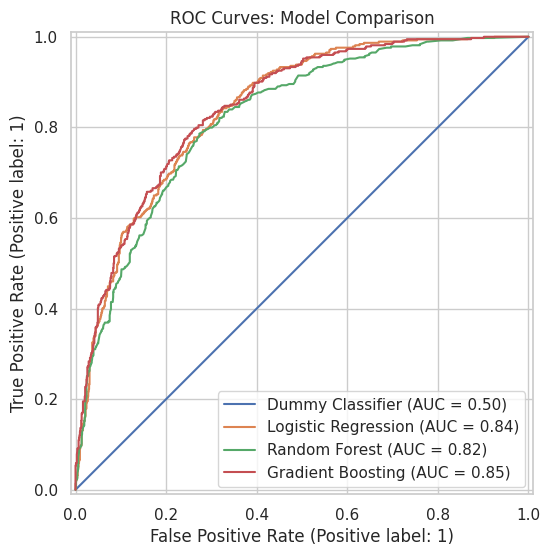

In [36]:
plt.figure(figsize=(8, 6))

for name, pipeline in pipelines.items():
    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curves: Model Comparison")
plt.show()

,Feature,Importance,Std
4,tenure,0.153662,0.004768
7,InternetService,0.042721,0.008108
17,MonthlyCharges,0.039928,0.006111
14,Contract,0.039288,0.004196
18,TotalCharges,0.011394,0.002249
13,StreamingMovies,0.004578,0.002023
8,OnlineSecurity,0.004232,0.001430
12,StreamingTV,0.004059,0.002590
11,TechSupport,0.003637,0.001103
16,PaymentMethod,0.003334,0.001657


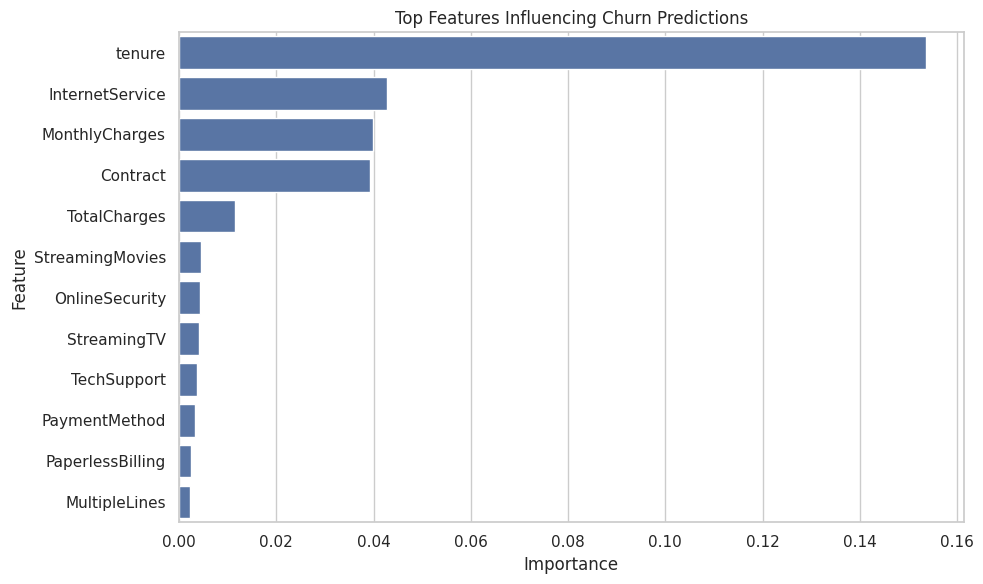

In [37]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(12),
    x="Importance",
    y="Feature"
)

plt.title("Top Features Influencing Churn Predictions")
plt.tight_layout()
plt.show()

In [39]:
from sklearn.metrics import precision_recall_curve

# Get predicted probabilities
logistic_model = pipelines["Logistic Regression"]
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate different thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_threshold_pred),
        "Recall": recall_score(y_test, y_threshold_pred),
        "F1 Score": f1_score(y_test, y_threshold_pred)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.30,0.429,0.928,0.587
1,0.35,0.447,0.904,0.598
2,0.40,0.467,0.866,0.607
3,0.45,0.483,0.840,0.613
4,0.50,0.504,0.783,0.614
5,0.55,0.525,0.751,0.618
6,0.60,0.540,0.706,0.612


In [40]:
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

print("Best threshold:", best_threshold["Threshold"])
print("Precision:", best_threshold["Precision"])
print("Recall:", best_threshold["Recall"])
print("F1 Score:", best_threshold["F1 Score"])

Best threshold: 0.55
Precision: 0.525233644859813
Recall: 0.7513368983957219
F1 Score: 0.6182618261826183


              precision    recall  f1-score   support

      Stayed       0.89      0.75      0.82      1035
     Churned       0.53      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.77      1409



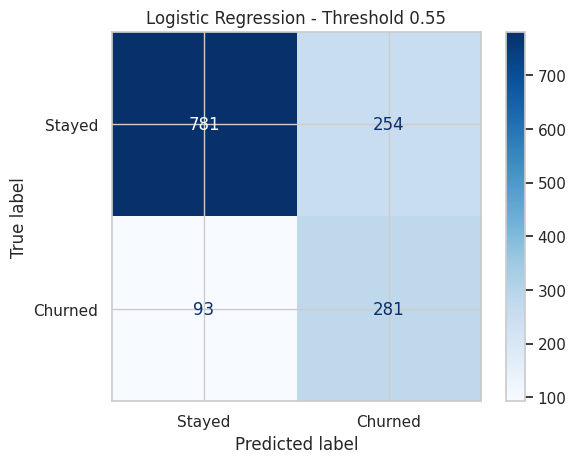

In [41]:
selected_threshold = 0.55

y_final_pred = (
    logistic_model.predict_proba(X_test)[:, 1] >= selected_threshold
).astype(int)

print(classification_report(
    y_test,
    y_final_pred,
    target_names=["Stayed", "Churned"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_final_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Logistic Regression - Threshold 0.55")
plt.show()

In [42]:
import joblib
import os

# Create folder for saved model
os.makedirs("models", exist_ok=True)

# Save the complete pipeline
joblib.dump(
    pipelines["Logistic Regression"],
    "models/logistic_regression_churn_pipeline.pkl"
)

# Save the selected classification threshold
joblib.dump(
    0.55,
    "models/churn_threshold.pkl"
)

print("Model and threshold saved successfully!")

Model and threshold saved successfully!
